In [3]:
#funções para incializar
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

def dixon(s23,s46):
    
    rw = (s46 + s23)/2
    rf = (s46 - s23)/2
         
    ff = rf / (rf + rw)
    
    return(ff)

## Como o sinal da gordura interfere na quantificação por Dixon, dada ausência de efeito T2*?
### Simulação %FF vs %Fdixon, T2\* *infinito*.
Objetivo: 
* Verificar a relação entre a quantidade real de gordura e o erro na quantificação apresentado pelo método de Dixon, na  hipotética ausência de efeito T2\*, como apresentado por [Chebrolu][1].

[1]: https://www.ncbi.nlm.nih.gov/pubmed/18093781?dopt=Abstract "Chebrolu et al"

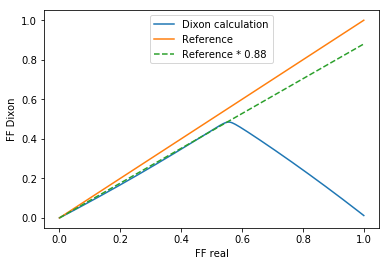

In [4]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

FF = np.linspace(0, 1, 200)
FFdixon = (len(FF))
FFdixon=np.zeros(FFdixon)
FFreal = (len(FF))
FFreal=np.zeros(FFreal)

for iteration,fatPercent in enumerate(FF):

    rho = [fatPercent*0.047,\
      fatPercent*0.039,\
      fatPercent*0.006,\
      fatPercent*0.12,\
      fatPercent*0.7,\
      fatPercent*0.088,\
      1-fatPercent] #water
    
    #para plotar somente os 7 pontos
    
    t = [0.0011515,  \
         0.0011515*2]
    """
    #para plotar a curva toda
    t = np.linspace(0, 0.05, 1000)
    """
    
    t2star = [0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023]

    Fppmn = [5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7]

    Fppmn = np.array(Fppmn)

    freq = [0,0,0,0,0,0,0]
    magField = 3.0 #tesla
    hydroGyro = 42.57e6 #Hz/T
    freq = np.array(freq)

    counter = [0,1,2,3,4,5,6]
    for n in counter:
        freq[n] = Fppmn[n]*magField*hydroGyro/1e6

    rho = np.array(rho)
    t = np.array(t)
    t2star = np.array(t2star)


    S = (7,len(t))
    S = np.zeros(S,dtype='complex')
    Sfinal= (len(t))
    Sfinal=np.zeros(Sfinal,dtype='complex')

    for n in counter:
        for index,TE in enumerate(t):
            S[n,index] = 0.1*rho[n]*np.exp(-TE/np.inf)*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    Sfinal = np.sum(S, axis=0)
    Sfinal = np.absolute(Sfinal)
    
    FFdixon[iteration] = dixon(Sfinal[0],Sfinal[1])
    FFreal[iteration] = fatPercent

fig, ax = plt.subplots()    
ax.plot(FFreal,FFdixon,'-', label="Dixon calculation")
ax.plot(FFreal,FFreal,'-', label="Reference")
ax.plot(FFreal,0.88*FFreal,'--', label="Reference * 0.88")
legend = ax.legend(loc='upper center')
plt.xlabel('FF real')
plt.ylabel('FF Dixon')
plt.show()


Pode ser observada uma relação de erro linear no cálculo de Dixon até FF = 50%, de aproximadamente 0.88 vezes o valor real de fração de gordura. Este erro pode ser explicado pelo fato de que este método de cálculo considera que toda a gordura está localizada em uma única componente espectral a 1.3 ppm, justificando os TEs escolhidos. Nesta simulação foram utilizadas 6 componentes, condizendo com os achados *in vivo* por [Hamilton][2], portanto "faltando" componentes a serem observadas para um cálculo mais completo. Vale lembrar que esta simulação é isenta ainda de ruído.
[2]: [http://www.pubmedcentral.nih.gov/articlerender.fcgi?artid=3860876&tool=pmcentrez&rendertype=abstract] "Hamilton et al."